In [4]:

import numpy as np
import matplotlib.pyplot as plt

def sir_derivatives(S, I, R, beta, gamma):
    dSdt = -beta * S * I
    dIdt = beta * S * I - gamma * I
    dRdt = gamma * I

    return dSdt, dIdt, dRdt


In [5]:

dS, dI, dR = sir_derivatives(
    S=1995,
    I=5,
    R=0,
    beta=0.000125,
    gamma=0.1
)

print("dS/dt =", dS)
print("dI/dt =", dI)
print("dR/dt =", dR)
print("Total rate =", dS + dI + dR)


dS/dt = -1.2468750000000002
dI/dt = 0.7468750000000002
dR/dt = 0.5
Total rate = 0.0


In [6]:

def simulate_sir(S0, I0, R0, beta, gamma, days, dt=0.1):
    steps = int(round(days / dt))

    t = np.linspace(0, days, steps + 1)

    S = np.zeros(steps + 1)
    I = np.zeros(steps + 1)
    R = np.zeros(steps + 1)

    S[0] = S0
    I[0] = I0
    R[0] = R0

    for n in range(steps):
        dS, dI, dR = sir_derivatives(
            S[n], I[n], R[n], beta, gamma
        )

        # Forward Euler:
        S[n + 1] = S[n] - dt * beta * S[n] * I[n]
        I[n + 1] = I[n] + dt * (beta * S[n] * I[n] - gamma * I[n])
        R[n + 1] = R[n] + dt * gamma * I[n]
        
    return t, S, I, R


In [7]:

t, S, I, R = simulate_sir(
    S0=1995,
    I0=5,
    R0=0,
    beta=0.000125,
    gamma=0.1,
    days=160,
    dt=0.1
)

N = S[0] + I[0] + R[0]

print("Initial population:", N)
print("Final population:", S[-1] + I[-1] + R[-1])
print("Population conserved:",
      np.allclose(S + I + R, N))

print("All populations nonnegative:",
      np.all(S >= 0) and np.all(I >= 0) and np.all(R >= 0))


Initial population: 2000.0
Final population: 1999.9999999999977
Population conserved: True
All populations nonnegative: True


In [8]:

# Part B: SIR Model Simulation

N = 2000
S0, I0, R0 = 1995, 5, 0

beta = 0.125e-3
gamma = 0.1

days = 160
dt = 0.1

t, S, I, R = simulate_sir(
    S0, I0, R0, beta, gamma, days, dt
)

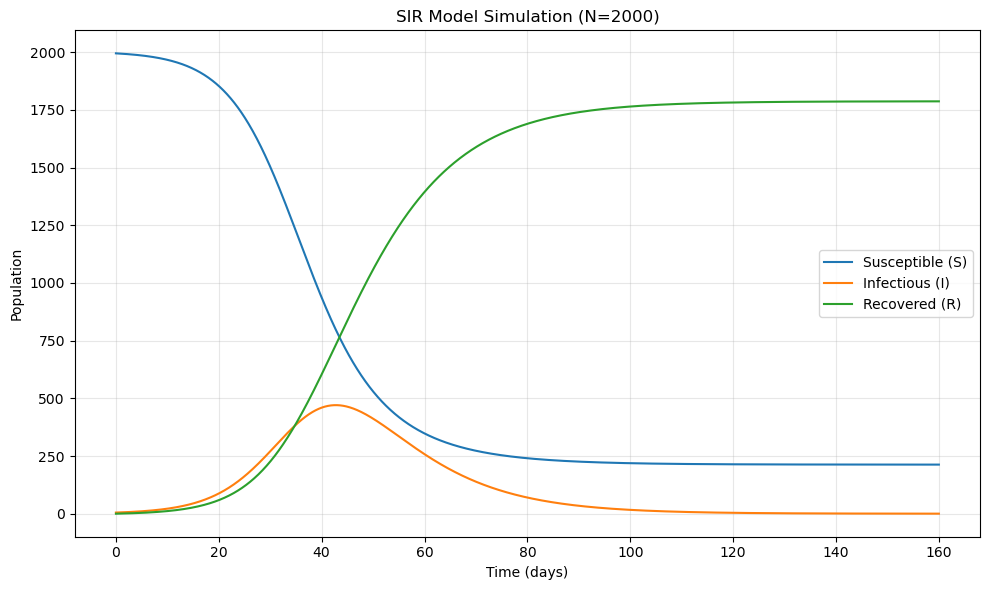

In [9]:

plt.figure(figsize=(10, 6))

plt.plot(t, S, label="Susceptible (S)")
plt.plot(t, I, label="Infectious (I)")
plt.plot(t, R, label="Recovered (R)")

plt.xlabel("Time (days)")
plt.ylabel("Population")
plt.title("SIR Model Simulation (N=2000)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("partB_sir.png", dpi=300)
plt.show()


In [10]:

print("Initial population:",
      S[0] + I[0] + R[0])

print("Final population:",
      S[-1] + I[-1] + R[-1])

print("Population conserved:",
      np.allclose(S + I + R, N))

print("Susceptible monotonically decreasing:",
      np.all(np.diff(S) <= 0))

print("Recovered monotonically increasing:",
      np.all(np.diff(R) >= 0))


Initial population: 2000.0
Final population: 1999.9999999999977
Population conserved: True
Susceptible monotonically decreasing: True
Recovered monotonically increasing: True


In [11]:

# Part C.i: Infection peak

peak_idx = np.argmax(I)

peak_day = t[peak_idx]
peak_infected = I[peak_idx]

print(f"Peak day: {peak_day:.2f}")
print(f"Peak infected: {peak_infected:.2f}")
print(f"Susceptible at peak: {S[peak_idx]:.2f}")


Peak day: 42.70
Peak infected: 470.46
Susceptible at peak: 799.88


In [12]:

critical_S = gamma / beta

print(f"Theoretical S at peak: {critical_S:.2f}")
print(f"Simulated S at peak: {S[peak_idx]:.2f}")
print(f"Difference: {S[peak_idx] - critical_S:.2f}")


Theoretical S at peak: 800.00
Simulated S at peak: 799.88
Difference: -0.12


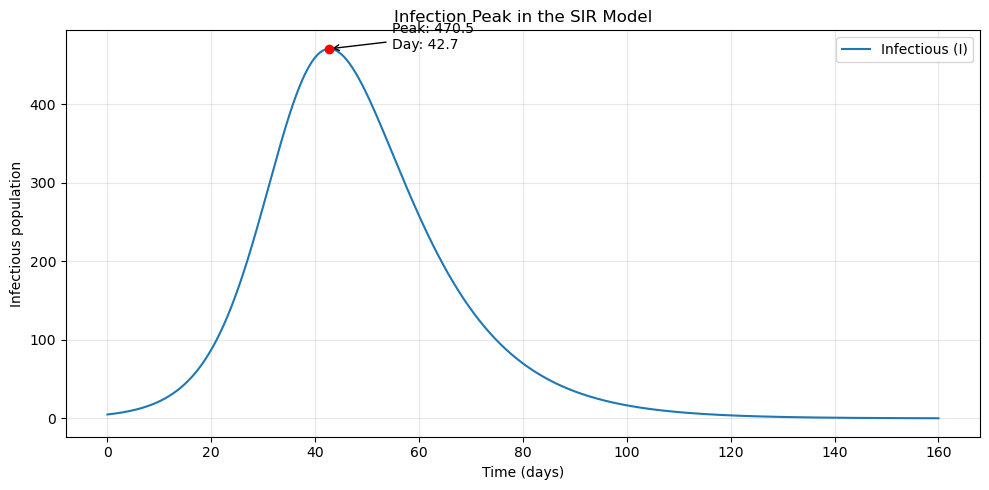

In [13]:

plt.figure(figsize=(10, 5))

plt.plot(t, I, label="Infectious (I)")

plt.scatter(peak_day, peak_infected,
            color="red", zorder=5)

plt.annotate(
    f"Peak: {peak_infected:.1f}\nDay: {peak_day:.1f}",
    xy=(peak_day, peak_infected),
    xytext=(peak_day + 12, peak_infected),
    arrowprops=dict(arrowstyle="->")
)

plt.xlabel("Time (days)")
plt.ylabel("Infectious population")
plt.title("Infection Peak in the SIR Model")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("partC_peak.png", dpi=300)
plt.show()


In [14]:

# Part C.ii: Basic reproduction number

R0_basic = beta * N / gamma

print(f"Basic reproduction number: {R0_basic:.2f}")


Basic reproduction number: 2.50


In [15]:

# Part C.iii: Epidemic dynamics

never_infected = S[-1]
ever_infected = N - S[-1]

print(f"Never infected by day 160: {never_infected:.2f}")
print(f"Ever infected by day 160: {ever_infected:.2f}")
print(f"Currently infectious: {I[-1]:.2f}")
print(f"Recovered: {R[-1]:.2f}")


Never infected by day 160: 212.79
Ever infected by day 160: 1787.21
Currently infectious: 0.20
Recovered: 1787.01


In [16]:

def seir_derivatives(S, E, I, R, N, beta, gamma, sigma, mu):
    dSdt = mu * N - beta * S * I - mu * S
    dEdt = beta * S * I - (sigma + mu) * E
    dIdt = sigma * E - (gamma + mu) * I
    dRdt = gamma * I - mu * R

    return dSdt, dEdt, dIdt, dRdt


In [17]:

def simulate_seir(S0, E0, I0, R0, beta, gamma,
                  sigma, mu, days, dt=0.1):

    steps = int(round(days / dt))
    t = np.arange(steps + 1) * dt

    S = np.zeros(steps + 1)
    E = np.zeros(steps + 1)
    I = np.zeros(steps + 1)
    R = np.zeros(steps + 1)

    S[0], E[0], I[0], R[0] = S0, E0, I0, R0

    N = S0 + E0 + I0 + R0

    for n in range(steps):
        dS, dE, dI, dR = seir_derivatives(
            S[n], E[n], I[n], R[n],
            N, beta, gamma, sigma, mu
        )

        S[n + 1] = S[n] + dt * dS
        E[n + 1] = E[n] + dt * dE
        I[n + 1] = I[n] + dt * dI
        R[n + 1] = R[n] + dt * dR

    return t, S, E, I, R


In [18]:

# Part D: Parameters

S0, E0, I0, R0 = 1980, 15, 5, 0

beta = 0.125e-3
gamma = 0.1
sigma = 0.25
mu = 0.005

# 365-day simulation
t365, S365, E365, I365, R365 = simulate_seir(
    S0, E0, I0, R0, beta, gamma, sigma, mu, 365
)

# 1500-day simulation
t1500, S1500, E1500, I1500, R1500 = simulate_seir(
    S0, E0, I0, R0, beta, gamma, sigma, mu, 1500
)


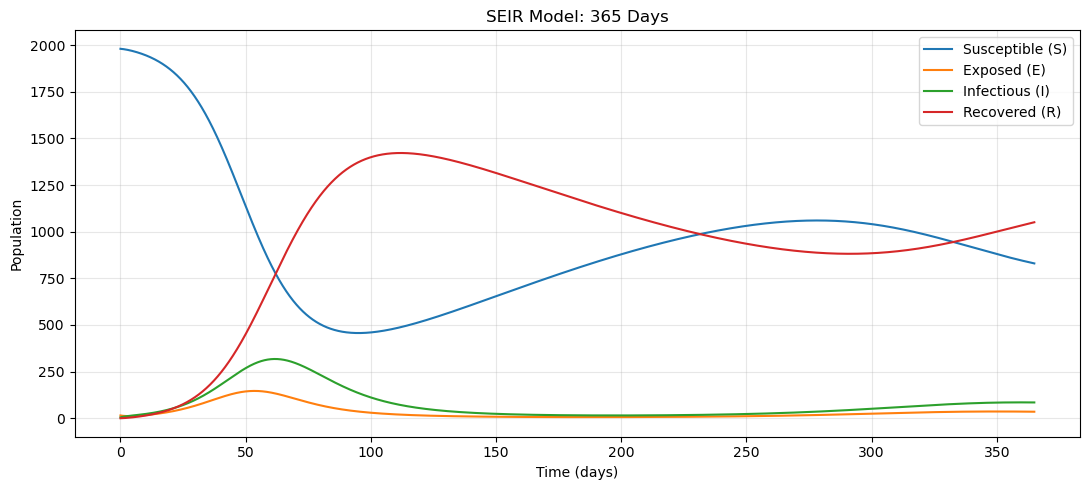

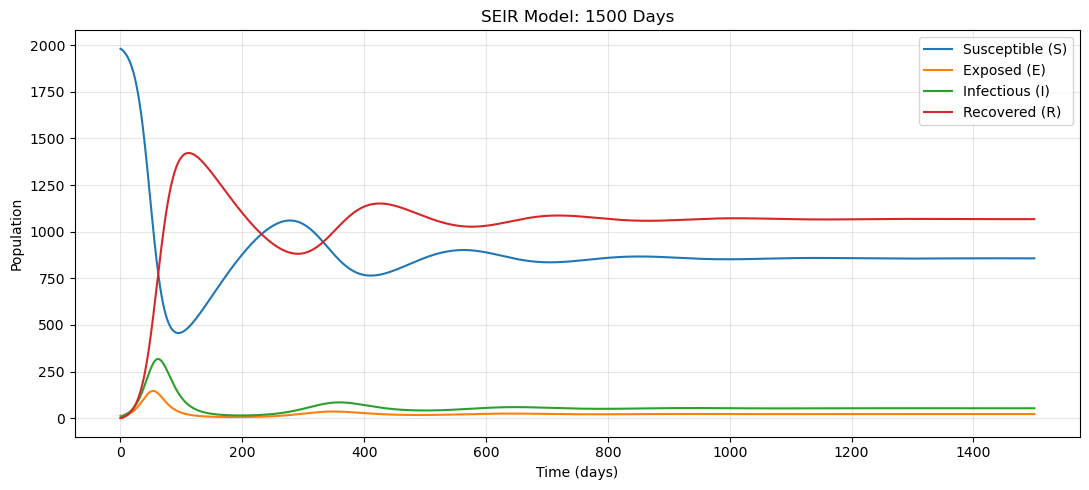

In [19]:

def plot_seir(t, S, E, I, R, title, filename):
    plt.figure(figsize=(11, 5))

    plt.plot(t, S, label="Susceptible (S)")
    plt.plot(t, E, label="Exposed (E)")
    plt.plot(t, I, label="Infectious (I)")
    plt.plot(t, R, label="Recovered (R)")

    plt.xlabel("Time (days)")
    plt.ylabel("Population")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(filename, dpi=300)
    plt.show()


plot_seir(t365, S365, E365, I365, R365,
          "SEIR Model: 365 Days", "partD_365.png")

plot_seir(t1500, S1500, E1500, I1500, R1500,
          "SEIR Model: 1500 Days", "partD_1500.png")


In [20]:

total = S1500 + E1500 + I1500 + R1500

print("Maximum population conservation error:",
      np.max(np.abs(total - 2000)))

assert np.allclose(total, 2000)
assert all(np.all(x >= 0) for x in
           [S1500, E1500, I1500, R1500])


Maximum population conservation error: 6.821210263296962e-12


In [21]:

from scipy.signal import find_peaks

peaks, _ = find_peaks(I1500, prominence=1.0)

print("Detected infection waves:")
for p in peaks:
    print(f"Day {t1500[p]:.1f}: {I1500[p]:.2f} infectious")


Detected infection waves:
Day 61.7: 317.60 infectious
Day 359.4: 85.09 infectious
Day 648.0: 59.66 infectious
Day 937.8: 54.76 infectious


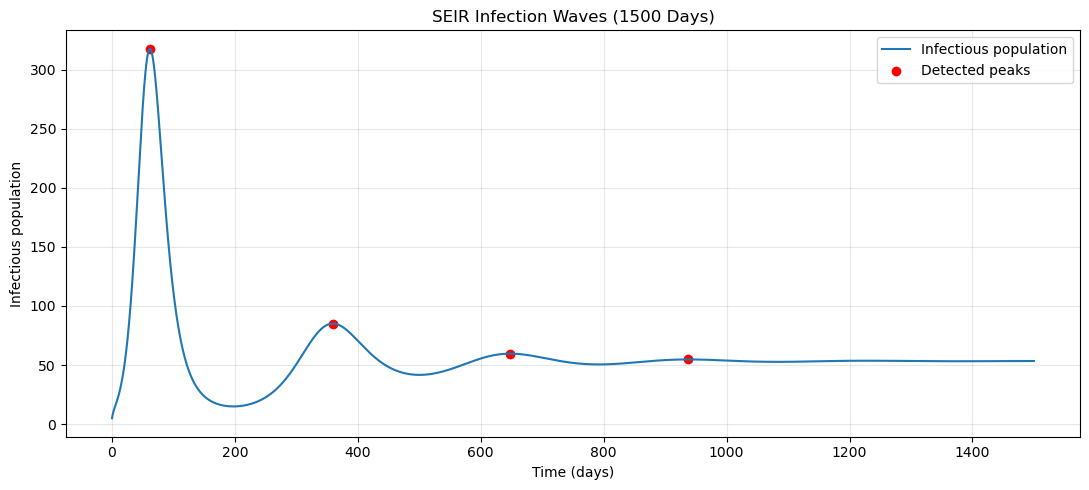

In [22]:

plt.figure(figsize=(11, 5))
plt.plot(t1500, I1500, label="Infectious population")
plt.scatter(t1500[peaks], I1500[peaks],
            color="red", label="Detected peaks")

plt.xlabel("Time (days)")
plt.ylabel("Infectious population")
plt.title("SEIR Infection Waves (1500 Days)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("partD_waves.png", dpi=300)
plt.show()


In [23]:

R0_seir = beta * 2000 * sigma / (
    (sigma + mu) * (gamma + mu)
)

S_equilibrium = 2000 / R0_seir

print(f"SEIR R0: {R0_seir:.4f}")
print(f"Theoretical equilibrium S: {S_equilibrium:.2f}")
print(f"Simulated S at day 1500: {S1500[-1]:.2f}")
print(f"Difference: {S1500[-1] - S_equilibrium:.2f}")


SEIR R0: 2.3343
Theoretical equilibrium S: 856.80
Simulated S at day 1500: 856.92
Difference: 0.12


In [24]:

# Part E.i: Parameter grid

beta_values = np.linspace(0.05e-3, 0.25e-3, 11)
gamma_values = np.linspace(0.05, 0.25, 11)

peak_infected = np.zeros((len(gamma_values), len(beta_values)))
total_infections = np.zeros_like(peak_infected)

print("Beta values:", beta_values)
print("Gamma values:", gamma_values)
print("Number of simulations:", peak_infected.size)


Beta values: [5.0e-05 7.0e-05 9.0e-05 1.1e-04 1.3e-04 1.5e-04 1.7e-04 1.9e-04 2.1e-04
 2.3e-04 2.5e-04]
Gamma values: [0.05 0.07 0.09 0.11 0.13 0.15 0.17 0.19 0.21 0.23 0.25]
Number of simulations: 121


In [27]:

# Part E.i: Run parameter sweep

for i, gamma_val in enumerate(gamma_values):
    for j, beta_val in enumerate(beta_values):

        t, S, E, I, R = simulate_seir(
            S0=1980,
            E0=15,
            I0=5,
            R0=0,
            beta=beta_val,
            gamma=gamma_val,
            sigma=0.25,
            mu=0.005,
            days=365,
            dt=0.1
        )

        # Peak infectious population
        peak_infected[i, j] = np.max(I)

        # Total new infections
        new_infection_rate = beta_val * S * I
        total_infections[i, j] = np.trapz(
            new_infection_rate, t
        )

print("Parameter sweep completed.")


Parameter sweep completed.


In [28]:
peak_infected[i, j] = np.max(I)

In [30]:
new_infection_rate = beta_val * S * I
total_infections[i, j] = np.trapz(new_infection_rate, t)

In [31]:

# R0 for all parameter combinations

N = 2000
sigma = 0.25
mu = 0.005

B, G = np.meshgrid(beta_values, gamma_values)

R0_grid = (B * N * sigma) / (
    (sigma + mu) * (G + mu)
)


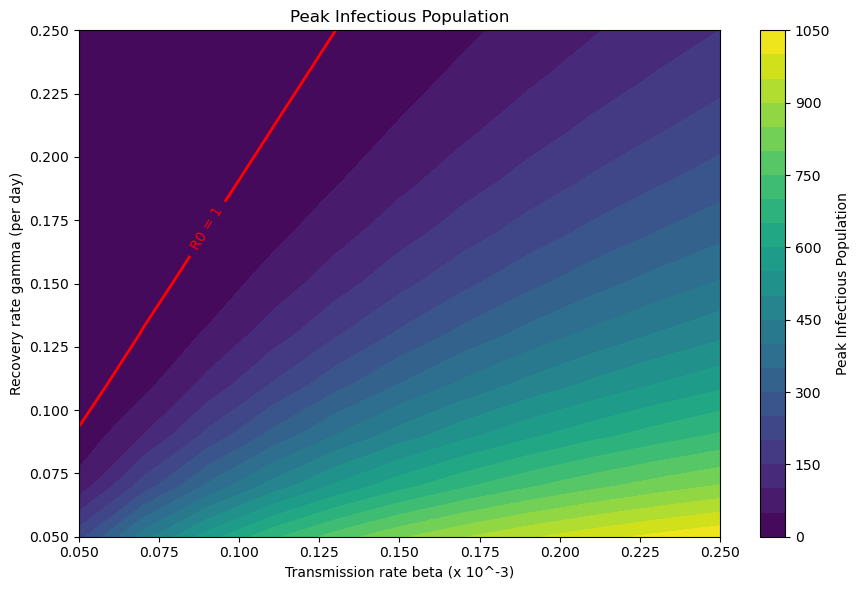

In [32]:

plt.figure(figsize=(9, 6))

cp = plt.contourf(
    B * 1e3,
    G,
    peak_infected,
    levels=20,
    cmap="viridis"
)

plt.colorbar(cp, label="Peak Infectious Population")

# Mark R0 = 1
boundary = plt.contour(
    B * 1e3, G, R0_grid,
    levels=[1.0],
    colors="red",
    linewidths=2
)

plt.clabel(boundary, fmt={1.0: "R0 = 1"})

plt.xlabel("Transmission rate beta (x 10^-3)")
plt.ylabel("Recovery rate gamma (per day)")
plt.title("Peak Infectious Population")

plt.tight_layout()
plt.savefig("partE_peak_heatmap.png", dpi=300)
plt.show()


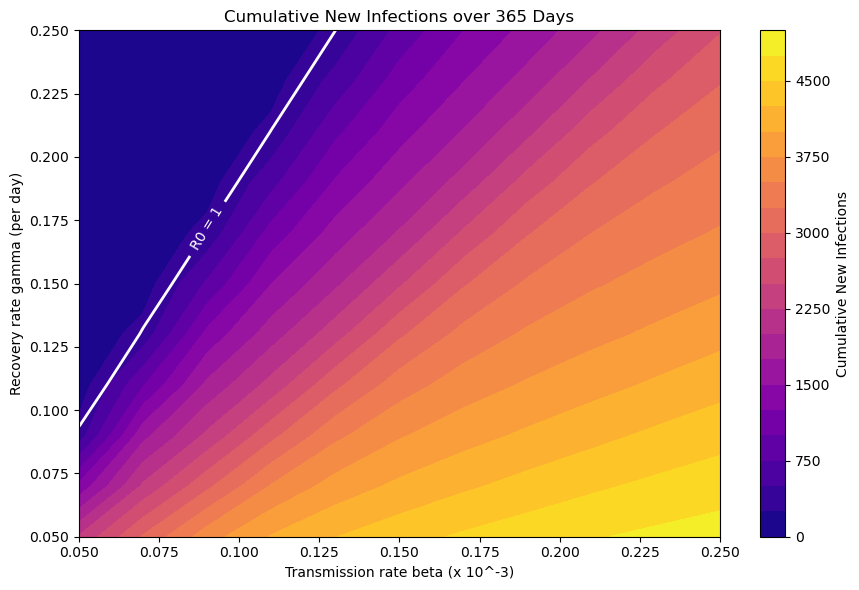

In [33]:

plt.figure(figsize=(9, 6))

cp = plt.contourf(
    B * 1e3,
    G,
    total_infections,
    levels=20,
    cmap="plasma"
)

plt.colorbar(cp, label="Cumulative New Infections")

boundary = plt.contour(
    B * 1e3, G, R0_grid,
    levels=[1.0],
    colors="white",
    linewidths=2
)

plt.clabel(boundary, fmt={1.0: "R0 = 1"})

plt.xlabel("Transmission rate beta (x 10^-3)")
plt.ylabel("Recovery rate gamma (per day)")
plt.title("Cumulative New Infections over 365 Days")

plt.tight_layout()
plt.savefig("partE_total_heatmap.png", dpi=300)
plt.show()
